# OSSE: Cold Pools in the Tropical Pacific

An observing system simulation experiment (OSSE) evaluates how well an observing system would observe a phenomenon by sampling a high-resolution model simulation (the *nature run*) as the system would. This example is an OSSE of **convective cold pools**: patches of air near the surface cooled by the evaporation of rain beneath showers and thunderstorms, which spread out as density currents, lift the air at their edges, and organize the convection of the tropical boundary layer. They are typically 5 to 50 km across and last an hour or two, so observing them is a test of both the resolution and the timing of an observing system.

The nature run is the **Hawaii test frame** of the EarthCARE mission (frame 39320E), a 250-m simulation by Environment and Climate Change Canada's GEM model along a 6,200 km stretch of EarthCARE's ground track over the central Pacific (Qu et al., 2023). The observing systems are those of the [monsoon OSSE](RunOSSEMonsoon.ipynb): the atmospheric sounders on the current NOAA/NASA polar-orbiting satellites (ATMS and CrIS) and two notional future sounders with finer resolution.

As in the monsoon and hurricane OSSEs, the experiment asks whether each feature is **observed** (does a sounder's swath cover it?) and **resolved** (does the part observed span at least a few resolution elements?). Unlike them, the nature run is a single snapshot rather than a sequence, so the experiment samples it during a window around its time, and its conclusions apply to this one scene.

The steps are:

1. configure the scenario and the nature run (the EarthCARE test frame);
2. define the features (cold pools) in the snapshot;
3. define the sensors (those of the monsoon OSSE);
4. compute the satellite passes over the frame with TAT-C;
5. determine whether each feature is observed and resolved by each sensor;
6. simulate what each sensor sees of the cold pools, as an image and an animation;
7. generate statistics; and
8. trade the design of the constellation: the number of satellites and their orbit planes.

The example requires the optional dependencies for OSSE examples (`pip install tatc[osse]`). Its first run downloads the part of the test frame it needs (about 750 MB, which takes from 10 to 45 minutes, as the server is slow to serve parts of files), and later runs take a few minutes.

## Configure the Scenario

The test frame is a snapshot of the atmosphere at 00:00 UTC on 24 June 2015, about 13:00 local solar time along the frame. Its 6,200 km by 200 km strip runs from 28 S to 27 N along 160 to 170 W, to the west of the Hawaiian Islands, and crosses the trade-wind regions of both hemispheres, the Intertropical Convergence Zone (ITCZ), and a weak front at its southern end.

A snapshot has no evolution, so the experiment assumes that it represents the scene for a window of `HALF_WINDOW` (one hour) on either side of its time, roughly the lifetime of a cold pool: a feature is observed if a swath covers it during the window. The satellites are those of the monsoon OSSE, with element sets at 00:00 UTC on 16 July 2026, and observe the snapshot as if it were taken at that time (`snapshot`). Their orbits are sun-synchronous, so the local times of their passes do not depend on the date, but which passes cross the frame within the window does; this is one realization, and the constellation trade averages over many.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

NATURE_TIME = datetime(
    2015, 6, 24, tzinfo=timezone.utc
)  # the time of the nature run's snapshot
# the time at which the satellites observe the snapshot (the epoch of their element sets), and the window around it in
# which the snapshot represents the scene
snapshot = datetime(2026, 7, 16, tzinfo=timezone.utc)
HALF_WINDOW = timedelta(minutes=60)
start, end = snapshot - HALF_WINDOW, snapshot + HALF_WINDOW

## Configure the Nature Run

The EarthCARE test frames were made to test the mission's retrieval algorithms before launch (Qu et al., 2023). GEM was run in four nested domains, at 10, 2.5, 1, and 0.25 km, initialized at 12:00 UTC on 23 June 2015, and the 13 innermost domains (each 500 km along the track and 200 km across) were joined into a frame on a 250 m grid. The frame is published on Zenodo in three parts under a CC BY 4.0 license; Part 1 (Qu et al., 2022) holds the atmospheric and surface properties used here. Its three-dimensional fields are on 200 levels of height, every 0.1 km from the surface, in netCDF (HDF5) files of 8 to 13 GB, compressed in chunks of 12 levels.

The example uses the air temperature on the lowest level above the sea surface (0.05 km), the surface precipitation rate, and the orography (which also gives the latitude and longitude of each cell). Rather than the whole 10 GB temperature file, it downloads only the compressed chunks that hold the lowest levels (about 560 MB), by HTTP range requests at the byte offsets that `h5py` reads from the file's index. Cold pools are kilometers to tens of kilometers across, so the fields are averaged to a 1 km grid (`COARSEN` cells of 250 m along and across the frame) and saved in a small file in a local `data` directory, so later runs are fast.

In [2]:
import io
import time
import warnings
import zlib
from concurrent.futures import ThreadPoolExecutor

import h5py
import requests
import xarray as xr

SCENE = "Test_data_39320E_2015062312"
PART_1 = 7196690  # Zenodo record of Part 1 of the Hawaii frame (atmospheric and surface properties)
ZENODO_URL = (
    "https://zenodo.org/api/records/{record}/files/" + SCENE + "_{name}.nc/content"
)
LEVEL = 1  # index of the 0.05 km level of height of the three-dimensional fields
COARSEN = 4  # cells of 250 m in each cell of 1 km, along and across the frame
FILL = -9e9  # the fill value of the frame's files


def get_bytes(url, start=None, end=None, tries=8):
    """The bytes of a URL (or of the range from start to end), retried with a backoff, as connections are sometimes
    dropped."""
    headers = {} if start is None else {"Range": f"bytes={start}-{end - 1}"}
    for attempt in range(tries):
        try:
            response = requests.get(url, headers=headers, timeout=600)
            response.raise_for_status()
            if start is None or len(response.content) == end - start:
                return response.content
        except requests.RequestException:
            pass
        time.sleep(min(60, 5 * 2**attempt))
    raise OSError(f"could not read {url}")


class RemoteFile(io.RawIOBase):
    """A read-only file at a URL, read by range requests in cached blocks, through which h5py reads a file's
    metadata."""

    BLOCK = 2**20

    def __init__(self, url):
        super().__init__()
        self.url, self.position, self.blocks = url, 0, {}
        response = requests.head(url, allow_redirects=True, timeout=60)
        self.size = int(response.headers["Content-Length"])

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.position

    def seek(self, offset, whence=io.SEEK_SET):
        origin = {io.SEEK_SET: 0, io.SEEK_CUR: self.position, io.SEEK_END: self.size}
        self.position = origin[whence] + offset
        return self.position

    def readinto(self, buffer):
        count = max(0, min(len(buffer), self.size - self.position))
        if count == 0:
            return 0
        first, last = (
            self.position // self.BLOCK,
            (self.position + count - 1) // self.BLOCK,
        )
        for block in range(first, last + 1):
            if block not in self.blocks:
                self.blocks[block] = get_bytes(
                    self.url,
                    block * self.BLOCK,
                    min(self.size, (block + 1) * self.BLOCK),
                )
        data = b"".join(self.blocks[block] for block in range(first, last + 1))
        offset = self.position - first * self.BLOCK
        buffer[:count] = data[offset : offset + count]
        self.position += count
        return count


def read_level(name, record=PART_1, level=LEVEL):
    """One level of a three-dimensional field of the frame (250 m cells), downloading only the chunks that hold it."""
    url = ZENODO_URL.format(record=record, name=name)
    with h5py.File(io.BufferedReader(RemoteFile(url), 2**16), "r") as f:
        variable = f[name]
        assert variable.compression == "gzip" and not variable.shuffle
        shape, chunks, dtype = variable.shape, variable.chunks, variable.dtype
        index = [
            variable.id.get_chunk_info(i) for i in range(variable.id.get_num_chunks())
        ]
    first = (
        level - level % chunks[2]
    )  # the first level of the chunks that hold the level
    field = np.full(shape[:2], np.nan, np.float32)

    def read_chunk(info):
        data = get_bytes(url, info.byte_offset, info.byte_offset + info.size)
        block = np.frombuffer(zlib.decompress(data), dtype).reshape(chunks)
        i, j, _ = info.chunk_offset
        field[i : i + chunks[0], j : j + chunks[1]] = block[
            : shape[0] - i, : shape[1] - j, level - first
        ]

    with ThreadPoolExecutor(6) as pool:
        list(
            pool.map(
                read_chunk, [info for info in index if info.chunk_offset[2] == first]
            )
        )
    return np.where(field <= FILL, np.nan, field)


def read_surface(name, record=PART_1):
    """A two-dimensional field of the frame (250 m cells), with the latitude and longitude of each cell."""
    with h5py.File(
        io.BytesIO(get_bytes(ZENODO_URL.format(record=record, name=name))), "r"
    ) as f:
        return {
            key: np.where(f[key][:] <= FILL, np.nan, f[key][:])
            for key in (name, "latitude", "longitude")
        }


def coarsen(field):
    """The means of blocks of COARSEN x COARSEN cells (ignoring missing values), dropping incomplete blocks."""
    rows, columns = field.shape[0] // COARSEN, field.shape[1] // COARSEN
    blocks = field[: rows * COARSEN, : columns * COARSEN].reshape(
        rows, COARSEN, columns, COARSEN
    )
    with warnings.catch_warnings():
        warnings.simplefilter(
            "ignore", RuntimeWarning
        )  # blocks without values (land, at 0.05 km)
        return np.nanmean(blocks, axis=(1, 3)).astype(np.float32)


def load_nature():
    """The frame's fields on a 1 km grid (along and across the frame), downloaded and averaged once to DATA_DIR."""
    nature_file = DATA_DIR / "earthcare_hawaii_39320E_1km.nc"
    if not nature_file.exists():
        temperature = read_level("temperature")
        orography = read_surface("orography")
        precipitation = read_surface("total_precipitation_rate")
        longitude = (orography["longitude"] + 180) % 360 - 180
        dims = ("along", "across")
        xr.Dataset(
            {
                "temperature": (
                    dims,
                    coarsen(temperature),
                    {"units": "K", "long_name": "air temperature at 0.05 km"},
                ),
                "precipitation": (
                    dims,
                    coarsen(precipitation["total_precipitation_rate"])
                    * np.float32(3.6e6),
                    {"units": "mm h-1", "long_name": "surface precipitation rate"},
                ),
                "orography": (dims, coarsen(orography["orography"]), {"units": "m"}),
                "lat": (
                    dims,
                    coarsen(orography["latitude"]),
                    {"units": "degrees_north"},
                ),
                "lon": (dims, coarsen(longitude), {"units": "degrees_east"}),
            }
        ).to_netcdf(nature_file)
    return xr.load_dataset(nature_file)


nature = load_nature()
nature

<xarray.Dataset> Size: 25MB
Dimensions:        (along: 6200, across: 200)
Dimensions without coordinates: along, across
Data variables:
    temperature    (along, across) float32 5MB 292.1 292.1 292.1 ... 296.3 295.9
    precipitation  (along, across) float32 5MB 14.17 13.57 ... 0.8873 0.2887
    orography      (along, across) float32 5MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    lat            (along, across) float32 5MB -27.98 -27.98 ... 27.14 27.14
    lon            (along, across) float32 5MB -169.7 -169.7 ... -160.9 -160.9

## Define the Environmental Features

A cold pool is a patch of air near the surface that is colder than its surroundings. Its **anomaly** here is the difference between the air temperature at 0.05 km and a background: the median across the frame (which is narrower than the scales over which the background varies), smoothed along the frame by a Gaussian of standard deviation `BACKGROUND_KM`. Features are contiguous patches whose anomaly is at most `ANOMALY_K` (-1 K, a common threshold for cold pools over the tropical oceans) and whose size (the diameter of a circle of the same area) is at least `MIN_DIAMETER_KM`. That is several times the effective resolution of a 250 m model and smaller than any of the sensors' footprints, so the sensors can be compared on all features. Cells over land (two small islands, Niue and the edge of Niihau) are excluded, and so is the frame south of `SOUTH_LIMIT`, where the anomaly would mostly be the cold air mass behind the front rather than cold pools.

`tatc.preprocess.find_features` finds the patches on the frame's curvilinear grid (the latitude and longitude of each 1 km cell) and, for each feature, records its area, size, centroid, position in the frame (kilometers along and across), coldest anomaly, and highest precipitation rate; the notebook adds whether it touches the long edges of the frame, beyond which it may extend unseen.

In [3]:
import scipy.ndimage as ndi
import xarray as xr

from tatc.preprocess import find_features

ANOMALY_K = (
    -1.0
)  # K, the anomaly of the air temperature at 0.05 km at most which a cell is in a cold pool
BACKGROUND_KM = (
    100  # km, the standard deviation of the smoothing of the background along the frame
)
MIN_DIAMETER_KM = 5  # km, the smallest feature
SOUTH_LIMIT = -20  # deg, the southern limit of the features (north of the front)
LAND_M = 1  # m, the orography above which a cell is land (one of the frame's domains has 0.0068 m over the ocean)
CELL_KM = 1  # km, the size of the cells of the 1 km grid


def frame_field(values, name=None):
    """Values of the cells of the frame's 1 km grid, as a field of a curvilinear grid (see `sample_field` and
    `find_features`) whose cells are each 1 km2."""
    dims = ("along", "across")
    return xr.DataArray(
        values,
        dims=dims,
        coords={
            "lat": (dims, nature.lat.values),
            "lon": (dims, nature.lon.values),
            "cell_area": (dims, np.full(values.shape, (CELL_KM * 1e3) ** 2)),
        },
        name=name,
    )


def find_cold_pools(nature):
    """The features (contiguous cold pools at least MIN_DIAMETER_KM in size, see `find_features`), and the anomaly,
    whether in a feature, and the label of the feature of each cell."""
    temperature = nature.temperature.where(nature.orography < LAND_M).values
    with warnings.catch_warnings():
        warnings.simplefilter(
            "ignore", RuntimeWarning
        )  # rows without values, filled below
        median = np.nanmedian(temperature, axis=1)
    rows = np.arange(len(median))
    median = np.interp(rows, rows[np.isfinite(median)], median[np.isfinite(median)])
    background = ndi.gaussian_filter1d(median, BACKGROUND_KM / CELL_KM, mode="nearest")
    anomaly = temperature - background[:, None]
    time = [np.datetime64(start.replace(tzinfo=None), "ns")]
    field = frame_field(anomaly, "anomaly")
    features, labels = find_features(
        ((field <= ANOMALY_K) & (field.lat >= SOUTH_LIMIT)).expand_dims(time=time),
        variables={
            "anomaly": field.expand_dims(time=time),
            "precipitation": frame_field(nature.precipitation.values).expand_dims(
                time=time
            ),
        },
        reductions=("min", "max"),
        min_diameter=MIN_DIAMETER_KM * 1e3,
        frame_duration=end - start,
        return_labels=True,
    )
    labels = labels.isel(time=0).values
    features["area_km2"] = features.area_m2 / 1e6
    features["diameter_km"] = features.diameter_m / 1e3
    # the position of each feature in the frame (km), and whether it touches the edges of the frame
    rows, columns = np.indices(labels.shape)
    features["along_km"] = ndi.mean(rows, labels, features.label) * CELL_KM
    features["across_km"] = ndi.mean(columns, labels, features.label) * CELL_KM
    features["at_edge"] = (ndi.minimum(columns, labels, features.label) == 0) | (
        ndi.maximum(columns, labels, features.label) == labels.shape[1] - 1
    )
    features = features[
        [
            "label",
            "area_km2",
            "diameter_km",
            "lon",
            "lat",
            "along_km",
            "across_km",
            "min_anomaly",
            "max_precipitation",
            "at_edge",
            "geometry",
            "start",
            "end",
        ]
    ]
    # the anomaly of each cell, whether it is in a feature, and the label of its feature (0 outside the features)
    return features, anomaly, labels > 0, labels


features, anomaly, in_feature, feature_labels = find_cold_pools(nature)
print(
    f"{len(features)} cold pools of {MIN_DIAMETER_KM} km or more, up to {features.diameter_km.max():.0f} km across "
    f"(median {features.diameter_km.median():.0f} km); {features.at_edge.sum()} touch the edges of the frame"
)
features.describe().round(2)

149 cold pools of 5 km or more, up to 79 km across (median 10 km); 21 touch the edges of the frame


,label,area_km2,diameter_km,lon,lat,along_km,across_km,min_anomaly,max_precipitation
count,149.00,149.00,149.00,149.00,149.00,149.00,149.00,149.00,149.00
mean,290.79,263.61,13.86,-164.25,5.33,3749.10,102.86,-1.82,17.47
std,175.04,583.65,12.02,2.73,14.31,1617.28,60.71,0.42,23.18
min,1.00,20.00,5.05,-169.07,-15.86,1369.73,2.16,-2.97,0.00
25%,123.00,32.00,6.38,-166.82,-11.11,1871.55,48.64,-2.09,3.78
50%,333.00,76.00,9.84,-164.45,5.17,3718.71,99.56,-1.82,8.93
75%,449.00,177.00,15.01,-161.80,19.38,5345.68,162.63,-1.50,22.44
max,540.00,4941.00,79.32,-159.16,27.10,6194.93,197.83,-1.08,133.37


The figure shows the anomaly along the whole frame (from south, left, to north, right; the frame is drawn 12 times wider than it is), with the cold pools outlined and the precipitation rate below. The cold pools lie under precipitating showers in the trade-wind regions of both hemispheres, and along a line of thunderstorms at 9 to 13 N. The ITCZ's large convective system near 3 N spreads a broad, weak anomaly under its rain, of which only parts are cold enough to be features. The front at the southern end, excluded, separates the warm air ahead of it (positive anomaly) from the cold air behind it. The frame's 13 domains meet every 500 km along the frame, where faint seams in the fields are visible.

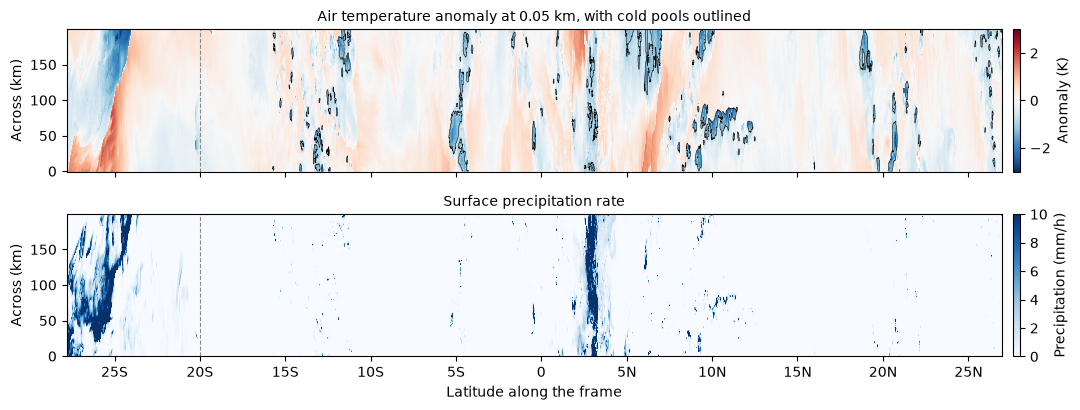

In [4]:
lat_center = nature.lat.values[:, nature.sizes["across"] // 2]
along = np.arange(nature.sizes["along"]) * CELL_KM
across = np.arange(nature.sizes["across"]) * CELL_KM
ticks = [np.abs(lat_center - value).argmin() for value in range(-25, 30, 5)]

fig, axes = plt.subplots(2, 1, figsize=(12, 4.2), sharex=True)
image = axes[0].pcolormesh(
    along,
    across,
    anomaly.T,
    cmap="RdBu_r",
    vmin=-3,
    vmax=3,
    shading="nearest",
    rasterized=True,
)
axes[0].contour(
    along, across, in_feature.T, levels=[0.5], colors="#0b0b0b", linewidths=0.4
)
fig.colorbar(image, ax=axes[0], pad=0.01, label="Anomaly (K)")
rain = axes[1].pcolormesh(
    along,
    across,
    nature.precipitation.values.T,
    cmap="Blues",
    vmin=0,
    vmax=10,
    shading="nearest",
    rasterized=True,
)
fig.colorbar(rain, ax=axes[1], pad=0.01, label="Precipitation (mm/h)")
for ax, title in zip(
    axes,
    [
        "Air temperature anomaly at 0.05 km, with cold pools outlined",
        "Surface precipitation rate",
    ],
):
    ax.axvline(
        along[np.abs(lat_center - SOUTH_LIMIT).argmin()],
        color="#8a8984",
        lw=0.8,
        ls="--",
    )
    ax.set(ylabel="Across (km)", title=title)
    ax.title.set_fontsize(10)
axes[1].set_xticks(
    along[ticks],
    [f"{abs(v)}{'N' if v > 0 else 'S' if v < 0 else ''}" for v in range(-25, 30, 5)],
)
axes[1].set_xlabel("Latitude along the frame")
fig.tight_layout()
plt.show()

## Define the Sensors

The sensors are those of the [monsoon OSSE](RunOSSEMonsoon.ipynb), which describes them in detail: the swaths of ATMS and CrIS from TAT-C's instrument catalog on NOAA-20 and NOAA-21 (the current constellation, since Suomi NPP was decommissioned), with their horizontal resolution and sample spacing, and a future microwave sounder and a future infrared sounder that share their swaths with 10 km and 3 km resolution.

| Sensor | Horizontal | Sampling |
| --- | --- | --- |
| ATMS | 32 km | 16 km |
| CrIS | 14 km | 16 km |
| Future MW | 10 km | 5 km |
| Future IR | 3 km | 3.4 km |

In [5]:
from tatc.catalog import get_entry
from tatc.schemas import GeneralPerturbationsOrbit, PointedInstrument, Satellite
from tatc.utils import compute_ground_inertial_velocity

# element sets (epoch 2026-07-16 00:00 UTC) from the JPSS TLE-AUX archive, as in the monsoon OSSE
tles = {
    "NOAA-20": [
        "1 43013U 17073A   26197.00000000  .00000069  00000-0  32863-4 0  1908",
        "2 43013  98.7768 136.2093 0001592 131.9807  15.3167 14.19516563448569",
    ],
    "NOAA-21": [
        "1 54234U 22150A   26197.00000000  .00000063  00000-0  30079-4 0  9591",
        "2 54234  98.7055 135.3072 0002920 108.6153 233.8084 14.19541053190632",
    ],
}
orbits = {name: GeneralPerturbationsOrbit.from_tle(tle) for name, tle in tles.items()}

# the instrument catalog's entries of ATMS and CrIS, and their swath configurations tested on NOAA-20
entries = {"ATMS": get_entry("atms"), "CrIS": get_entry("cris")}
SWATHS = {"ATMS": "swath_noaa_20", "CrIS": "swath"}
TIME_STEP = 30  # s, of the ground track


def sounder_satellite(name, orbit):
    """A satellite carrying the swaths of ATMS and CrIS (the catalog's swath configurations), tailored to the time
    step, with the attitude they were tested with (scanning perpendicular to the inertial velocity).
    """
    payloads = [
        entry.build(configuration=SWATHS[sensor], orbit=orbit, time_step=TIME_STEP)
        for sensor, entry in entries.items()
    ]
    return Satellite(
        name=name,
        orbit=orbit,
        instruments=[payload.instruments[0] for payload in payloads],
        attitude=payloads[0].attitude,
    )


satellites = [sounder_satellite(name, orbit) for name, orbit in orbits.items()]

REFERENCE_RANGE_KM = 830  # nominal slant range at nadir (altitude), at which the nominal resolutions apply
# angular spacing (deg) of the samples of each scan, from the catalog's configurations of their samples: the ATMS scan
# positions and the pitch of the CrIS 3 x 3 array of views
atms_beams = entries["ATMS"].configurations["beams_noaa_20"].instruments[0].parameters
cris_pixels = entries["CrIS"].configurations["pixels_noaa_20"].instruments[0].parameters
SAMPLING_DEG = {
    "ATMS": atms_beams["cross_track_field_of_view"] / atms_beams["cross_track_pixels"],
    "CrIS": cris_pixels["along_track_field_of_view"]
    / cris_pixels["along_track_pixels"],
}
# sensors: the scan (swath) they share, and their horizontal resolution at nadir (km)
sensors = pd.DataFrame(
    [
        {"sensor": "ATMS", "swath": "ATMS", "horizontal_km": 32},
        {"sensor": "CrIS", "swath": "CrIS", "horizontal_km": 14},
        {"sensor": "Future MW", "swath": "ATMS", "horizontal_km": 10},
        {"sensor": "Future IR", "swath": "CrIS", "horizontal_km": 3},
    ]
).set_index("sensor")
# sample spacing at nadir (km): that of the heritage sensor, scaled for the future sensors in proportion to their footprint
heritage_km = sensors.horizontal_km[sensors.swath].values
sensors["sampling_km"] = (
    REFERENCE_RANGE_KM
    * np.radians(sensors.swath.map(SAMPLING_DEG))
    * sensors.horizontal_km
    / heritage_km
)
# the time between scans (s) of the future sensors, each of which scans one row of samples every time the ground track
# advances by its sample spacing, so that its samples are spaced along track by that advance (ATMS and CrIS keep the
# angular pitch of their samples along track)
ground_speed_km_s = (
    compute_ground_inertial_velocity(orbits["NOAA-20"].get_mean_altitude()) / 1e3
)
sensors["scan_period_s"] = np.where(
    sensors.swath != sensors.index, sensors.sampling_km / ground_speed_km_s, np.nan
)


def sensor_instrument(sensor):
    """The swath instrument of a sensor with its pixels (for its sample sizes, see `compute_sample_sizes`): pixels
    spaced by the angle that the sample spacing subtends at nadir from the reference range (enough to span the
    swath), each with the instantaneous field of view that its horizontal resolution subtends, along and across
    track, and for a future sensor the time between its scans (`scan_period`), in which the ground track advances
    by its sample spacing."""
    row = sensors.loc[sensor]
    swath = satellites[1].instruments[list(entries).index(row.swath)]
    ifov = np.degrees(2 * np.arctan(row.horizontal_km / 2 / REFERENCE_RANGE_KM))
    spacing = np.degrees(row.sampling_km / REFERENCE_RANGE_KM)
    pixels = round(swath.cross_track_field_of_view / spacing)
    # the oversampling makes each pixel's field of view ifov (negative: a gap between pixels)
    return PointedInstrument(
        **swath.model_dump(
            exclude_unset=True,
            exclude={
                "cross_track_field_of_view",
                "along_track_field_of_view",
                "cross_track_pixels",
                "cross_track_oversampling",
                "along_track_oversampling",
                "scan_period",
            },
        ),
        cross_track_field_of_view=pixels * spacing,
        along_track_field_of_view=spacing,
        cross_track_pixels=pixels,
        cross_track_oversampling=1 - spacing / ifov,
        along_track_oversampling=1 - spacing / ifov,
        scan_period=None if np.isnan(row.scan_period_s) else row.scan_period_s,
    )


sensors.round(1)

,swath,horizontal_km,sampling_km,scan_period_s
sensor,,,,
ATMS,ATMS,32,16.1,NaN
CrIS,CrIS,14,15.8,NaN
Future MW,ATMS,10,5.0,0.8
Future IR,CrIS,3,3.4,0.5


## Compute the Satellite Passes

`collect_ground_track` returns the footprint of each instrument at each time step of the window, clipped to the frame (the `mask`), and their union is the part of the frame each swath covers (`swaths`). The satellites' orbits ascend near 13:30 local time, and the frame lies along EarthCARE's descending track at about 14:00, so their ground tracks cross it at a shallow angle, and a swath covers a long stretch of the frame on each pass.

In [6]:
from tatc.analysis import collect_ground_track

# the outline of the frame (its long edges, every 10 km, and its ends)
edges = [
    np.column_stack([nature.lon.values[::10, column], nature.lat.values[::10, column]])
    for column in (0, -1)
]
frame = shapely.Polygon(np.concatenate([edges[0], edges[1][::-1]]))


def collect_tracks(satellites):
    """The footprint of every instrument of the satellites at each time step of the window, clipped to the frame."""
    times = [
        start + timedelta(seconds=TIME_STEP * (i + 0.5))
        for i in range(int((end - start).total_seconds() // TIME_STEP))
    ]
    tracks = collect_ground_track(satellites, times, instrument_index=None, mask=frame)
    tracks = tracks[tracks.valid_obs].reset_index(drop=True)
    tracks["geometry"] = shapely.force_2d(tracks.geometry.values)
    return tracks


def number_passes(tracks):
    """The number of each satellite's pass over the frame in the window (separated by gaps of over 10 minutes)."""
    tracks = tracks.sort_values("time")
    gap = tracks.groupby("satellite").time.diff() > timedelta(minutes=10)
    return gap.groupby(tracks.satellite).cumsum().reindex(tracks.index) + 1


EQUAL_AREA = "EPSG:6933"  # an equal-area projection, for areas
tracks = collect_tracks(satellites)
tracks["pass"] = number_passes(tracks)
swaths = tracks.groupby(["satellite", "pass", "instrument"]).geometry.agg(
    shapely.union_all
)
frame_area = gpd.GeoSeries([frame], crs="EPSG:4326").to_crs(EQUAL_AREA).area.iloc[0]
passes = tracks.groupby(["satellite", "pass", "instrument"]).agg(
    first=("time", "min"), last=("time", "max")
)
passes["frame covered (%)"] = (
    100
    * gpd.GeoSeries(swaths.values, crs="EPSG:4326").to_crs(EQUAL_AREA).area.values
    / frame_area
)
passes["features in swath"] = [
    int(features.intersects(swath).sum()) for swath in swaths
]
for column in ("first", "last"):
    passes[column] = passes[column].dt.strftime("%H:%M UTC")
passes.round(0)

first       last  frame covered (%)  \
satellite pass instrument                                            
NOAA-20   1    ATMS        23:22 UTC  23:26 UTC               23.0   
               CrIS        23:23 UTC  23:26 UTC               15.0   
          2    ATMS        00:52 UTC  00:59 UTC               53.0   
               CrIS        00:52 UTC  00:59 UTC               53.0   
NOAA-21   1    ATMS        00:00 UTC  00:12 UTC               78.0   
               CrIS        00:01 UTC  00:12 UTC               68.0   

                           features in swath  
satellite pass instrument                     
NOAA-20   1    ATMS                       44  
               CrIS                       38  
          2    ATMS                       61  
               CrIS                       61  
NOAA-21   1    ATMS                      146  
               CrIS                      111

In this realization, three passes cross the frame in the window: NOAA-21 at 00:00 to 00:12 UTC, closest to the snapshot, whose ATMS swath covers 78% of the frame and 146 of its 149 cold pools; and NOAA-20 on two consecutive orbits, at 23:22 to 23:26 over the frame's northern end and at 00:52 to 00:59 over its southern half. Between them, the swaths of both sounders cover every cold pool.

The map shows where the frame lies, west of the Hawaiian Islands, and the swaths of ATMS (the wider swath; those of CrIS are slightly narrower) on the passes that cross it in the window, each labeled with its satellite and the times at which it crosses the frame. The cold pools are drawn as points at their centroids.

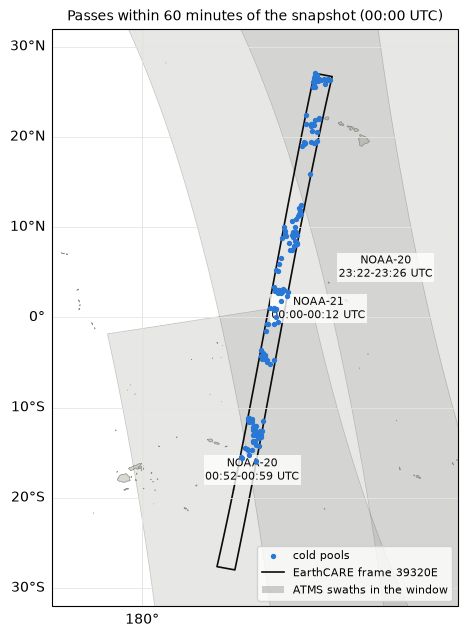

In [7]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#8a8984",
    "#0b0b0b",
)
# the swaths of ATMS in the window over a region around the frame (unclipped by the frame), per pass
REGION = shapely.box(-200, -35, -135, 35)
region_tracks = collect_ground_track(
    satellites,
    [
        start + timedelta(seconds=TIME_STEP * (i + 0.5))
        for i in range(int((end - start).total_seconds() // TIME_STEP))
    ],
    instrument_index=list(entries).index("ATMS"),
    mask=REGION,
)
region_tracks = region_tracks[region_tracks.valid_obs].reset_index(drop=True)
region_tracks["pass"] = number_passes(region_tracks)
fig, ax = plt.subplots(
    figsize=(7, 7.5), subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)}
)
ax.set_extent([-190, -145, -32, 32], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#d9d8d3")
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=GRAY, linewidth=0.5)
gridlines = ax.gridlines(draw_labels=True, color="#e6e5e0", linewidth=0.6)
gridlines.top_labels = gridlines.right_labels = False
for (satellite, number), group in region_tracks.groupby(["satellite", "pass"]):
    # only passes that cross the frame
    swath = shapely.union_all(shapely.force_2d(group.geometry.values))
    if not swath.intersects(frame):
        continue
    ax.add_geometries(
        [swath],
        crs=ccrs.PlateCarree(),
        facecolor=GRAY,
        edgecolor=INK,
        linewidth=0.5,
        alpha=0.2,
    )
    crossing = group[group.intersects(frame)].time
    # labeled at the center of the part of the swath on the map
    label_at = shapely.intersection(swath, shapely.box(-190, -32, -145, 32)).centroid
    ax.text(
        label_at.x,
        label_at.y,
        f"{satellite}\n{crossing.min():%H:%M}-{crossing.max():%H:%M} UTC",
        transform=ccrs.PlateCarree(),
        fontsize=8,
        color=INK,
        ha="center",
        va="center",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1},
    )
ax.add_geometries(
    [frame], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=INK, linewidth=1.2
)
ax.scatter(
    features.lon,
    features.lat,
    s=8,
    color=BLUE,
    transform=ccrs.PlateCarree(),
    zorder=3,
    label="cold pools",
)
ax.plot([], [], color=INK, lw=1.2, label="EarthCARE frame 39320E")
ax.add_patch(
    plt.Rectangle(
        (0, 0), 0, 0, facecolor=GRAY, alpha=0.4, label="ATMS swaths in the window"
    )
)
ax.legend(loc="lower right", fontsize=8)
ax.set_title(
    f"Passes within {HALF_WINDOW.seconds // 60} minutes of the snapshot ({snapshot:%H:%M} UTC)",
    fontsize=10,
)
plt.show()

## Compute Observability and Resolution

As in the monsoon OSSE, a feature is **observed** by a swath if the swath's footprint of some time step in the window overlaps it, a **look** is one satellite's view of the part of a feature inside its swath, and a feature is **resolved** if its viewed part spans at least `RESOLUTION_FACTOR` (two) resolution elements at its best look. TAT-C's `collect_feature_observations` collects the looks at features that exist for a period of time (here, the window), with the viewing geometry of each. The resolution element is the larger of a sensor's pixel and the spacing between its pixels, projected onto the ground at the look by TAT-C's `compute_sample_sizes`, with its size measured as the diameter of a circle of the same area (`ELEMENT_AXIS`). The statistics also give the share resolved with the footprint and the spacing added in quadrature (`"quadrature"`), a bound on the element where the two are similar (see the monsoon OSSE).

A satellite may pass over the frame twice within the window (on consecutive orbits, 101 minutes apart), in which case its look at a feature joins the parts of the feature that each pass views, at the time of the footprint that covers most of it.

In [8]:
from tatc.analysis import collect_feature_observations, compute_sample_sizes

RESOLUTION_FACTOR = 2  # a feature is resolved if its viewed part spans at least this many resolution elements
ELEMENT_AXIS = "equivalent"  # the size of a resolution element: "equivalent" (diameter of equal area), "cross-track",
# or "quadrature" (the equivalent diameter with the footprint and the spacing added in quadrature)
AXES = ["equivalent", "cross-track", "quadrature"]


def collect_looks(satellites, features):
    """The looks at the features (see `collect_feature_observations`): each satellite's view of the part of each
    feature inside its swath in the window, at the time of the footprint that covers most of it, with the size of the
    viewed part and the zenith angle at its centroid."""
    times = [
        start + timedelta(seconds=TIME_STEP * (i + 0.5))
        for i in range(int((end - start).total_seconds() // TIME_STEP))
    ]
    looks = collect_feature_observations(features, satellites, times)
    looks["viewed_km"] = np.sqrt(
        4 * looks.viewed_fraction * features.area_km2.values[looks.feature] / np.pi
    )
    looks["zenith"] = 90 - looks.platform_alt
    return looks


def assess(looks, features, satellites):
    """Whether each sensor observes and resolves each feature, from its best look."""
    results = []
    for sensor, row in sensors.iterrows():
        # the sizes of the sensor's samples at its looks, flown on the same satellites
        sensor_satellites = [
            satellite.model_copy(update={"instruments": [sensor_instrument(sensor)]})
            for satellite in satellites
        ]
        sensor_looks = compute_sample_sizes(
            looks[looks.instrument == row.swath], sensor_satellites
        )
        # the resolution element is the larger of a sample and the spacing between samples (km), along and across track
        along = np.maximum(sensor_looks.sample_along, sensor_looks.spacing_along) / 1e3
        cross = np.maximum(sensor_looks.sample_cross, sensor_looks.spacing_cross) / 1e3
        # or, as a bound, the two added in quadrature (as independent blurs)
        along_q = np.hypot(sensor_looks.sample_along, sensor_looks.spacing_along) / 1e3
        cross_q = np.hypot(sensor_looks.sample_cross, sensor_looks.spacing_cross) / 1e3
        for axis, element_km in {
            "equivalent": np.sqrt(along * cross),
            "cross-track": cross,
            "quadrature": np.sqrt(along_q * cross_q),
        }.items():
            sensor_looks[f"elements ({axis})"] = sensor_looks.viewed_km / element_km
            if axis == ELEMENT_AXIS:
                sensor_looks["element_km"] = element_km
        # the best look at each feature: the one whose viewed part spans the most resolution elements
        best = sensor_looks.loc[
            sensor_looks.groupby("feature")[f"elements ({ELEMENT_AXIS})"].idxmax()
        ].set_index("feature")
        result = features[
            [
                "diameter_km",
                "area_km2",
                "lat",
                "min_anomaly",
                "max_precipitation",
                "at_edge",
            ]
        ].copy()
        result["sensor"] = sensor
        result["looks"] = (
            sensor_looks.groupby("feature").size().reindex(result.index, fill_value=0)
        )
        result["observed"] = result.looks > 0
        result = result.join(
            best[
                [
                    "satellite",
                    "time",
                    "zenith",
                    "viewed_fraction",
                    "viewed_km",
                    "element_km",
                ]
            ]
        )
        for axis in AXES:
            result[f"elements ({axis})"] = sensor_looks.groupby("feature")[
                f"elements ({axis})"
            ].max()
        result["resolved"] = result[f"elements ({ELEMENT_AXIS})"] >= RESOLUTION_FACTOR
        results.append(result)
    return pd.concat(results).reset_index().rename(columns={"index": "feature"})


looks = collect_looks(satellites, features)
results = assess(looks, features, satellites)
results.groupby("sensor")[["observed", "resolved"]].sum().join(sensors).loc[
    sensors.index
].round(1)

,observed,resolved,swath,horizontal_km,sampling_km,scan_period_s
sensor,,,,,,
ATMS,149,1,ATMS,32,16.1,NaN
CrIS,149,10,CrIS,14,15.8,NaN
Future MW,149,23,ATMS,10,5.0,0.8
Future IR,149,98,CrIS,3,3.4,0.5


Every sensor observes all 149 cold pools, so in this scene the sensors differ only in resolution: ATMS resolves 1, CrIS 10, a future microwave sounder 23, and a future infrared sounder 98.

## Simulate What Each Sensor Sees

Observing and resolving are summaries; an image shows what they mean. This section simulates the image of the cold pools that each sensor would record on one pass over the stretch of the frame with the most cold pools (`SEGMENT_KM` along the frame), from the pass that covers most of it in the window.

TAT-C's `collect_ground_pixels` gives the center of each sample of a sensor (with the pixels of `sensor_instrument`) at each scan, with scans separated by the time in which the ground track advances by the sample spacing, and `compute_sample_sizes` gives the size of each sample's footprint along and across track, which grows toward the edges of the swath. Each sample's value is the anomaly averaged over its footprint, weighted by a Gaussian whose full width at half maximum is the footprint's size, over the part of the footprint inside the frame (the scene outside it is unknown): `sample_field` with `method="footprint"`, which orients each footprint by the `sample_azimuth` of its along-track axis on the ground. The image draws each sample as a tile of the sample spacing on the 1 km grid of the nature run. The tile is the area that each sample represents in an image, while its value is blurred over the footprint, which is larger than the tile for the microwave sounders (which oversample) and slightly smaller for the infrared sounders (whose views have small gaps between them, not drawn). Each cold pool is outlined by its status for each sensor on this pass alone (from the satellite's looks at the cold pools in the pass, assessed as above): resolved (black), observed but not resolved (orange), or not observed (dotted gray), and each panel counts the cold pools that the sensor resolves in the stretch.

In [9]:
from scipy.spatial import cKDTree

from tatc.analysis import collect_ground_pixels, sample_field
from tatc.utils import compute_ground_inertial_velocity

SEGMENT_KM = 450  # km, the length of the stretch of the frame imaged
TILE = 1.1  # the size of a sample's tile in the image, relative to the sample spacing

# the stretch with the most area in cold pools
in_stretch = np.convolve(
    in_feature.sum(axis=1), np.ones(int(SEGMENT_KM / CELL_KM)), mode="valid"
)
segment_rows = slice(
    int(in_stretch.argmax()), int(in_stretch.argmax() + SEGMENT_KM / CELL_KM)
)
segment = shapely.Polygon(
    np.concatenate(
        [
            np.column_stack(
                [nature.lon.values[segment_rows, 0], nature.lat.values[segment_rows, 0]]
            ),
            np.column_stack(
                [
                    nature.lon.values[segment_rows, -1],
                    nature.lat.values[segment_rows, -1],
                ]
            )[::-1],
        ]
    )
)
# the pass that covers most of the stretch, in both swaths
coverage = (
    swaths.apply(lambda swath: swath.intersection(segment).area)
    .groupby(["satellite", "pass"])
    .min()
)
pass_satellite, pass_number = coverage.idxmax()
satellite = next(s for s in satellites if s.name == pass_satellite)
pass_times = tracks[
    (tracks.satellite == pass_satellite) & (tracks["pass"] == pass_number)
].time
print(
    f"stretch: {lat_center[segment_rows.start]:.1f} to {lat_center[segment_rows.stop - 1]:.1f} deg latitude, "
    f"{features.along_km.between(segment_rows.start, segment_rows.stop).sum()} cold pools; "
    f"pass: {pass_satellite}, {pass_times.min():%H:%M}-{pass_times.max():%H:%M} UTC"
)


def unit_vectors(lon, lat):
    """Unit vectors (Earth-centered) of points on a sphere, for finding nearest neighbors."""
    lon, lat = np.radians(lon), np.radians(lat)
    return np.column_stack(
        [np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]
    )


# the anomaly as a field at the time of the pass (see `sample_field`)
field = frame_field(anomaly, "anomaly").expand_dims(
    time=[np.datetime64(start.replace(tzinfo=None), "ns")]
)
cell_tree = cKDTree(unit_vectors(nature.lon.values.ravel(), nature.lat.values.ravel()))
# derivatives of longitude and latitude by row and column of the frame
lon_row, lon_column = np.gradient(nature.lon.values.astype(float))
lat_row, lat_column = np.gradient(nature.lat.values.astype(float))


def to_frame(lon, lat):
    """The positions (km along and across the frame) of points: their nearest cell, refined by a linear step."""
    _, nearest = cell_tree.query(unit_vectors(lon, lat))
    i, j = np.unravel_index(nearest, nature.lon.shape)
    d_lon, d_lat = lon - nature.lon.values[i, j], lat - nature.lat.values[i, j]
    a, b, c, d = lon_row[i, j], lon_column[i, j], lat_row[i, j], lat_column[i, j]
    determinant = a * d - b * c
    return (
        (i + (d * d_lon - b * d_lat) / determinant) * CELL_KM,
        (j + (a * d_lat - c * d_lon) / determinant) * CELL_KM,
    )


def collect_samples(sensor):
    """The samples of a sensor on the pass over the stretch: their time, position in the frame (km), footprint and
    spacing (km), cross-track direction, and value (the anomaly averaged over the footprint, with Gaussian weights of
    its size, see `sample_field`, over the cells inside the frame).
    """
    row = sensors.loc[sensor]
    sensor_satellite = satellite.model_copy(
        update={"instruments": [sensor_instrument(sensor)]}
    )
    speed = (
        compute_ground_inertial_velocity(satellite.orbit.get_mean_altitude()) / 1e3
    )  # km/s
    step = timedelta(seconds=row.sampling_km / speed)
    first = pass_times.min() - timedelta(seconds=TIME_STEP)
    last = pass_times.max() + timedelta(seconds=TIME_STEP)
    times = [first + k * step for k in range(int((last - first) / step) + 1)]
    pixels = collect_ground_pixels(sensor_satellite, times, mask=segment.buffer(0.5))
    pixels = compute_sample_sizes(
        pixels[pixels.valid_obs].reset_index(drop=True), sensor_satellite
    )
    pixels = sample_field(
        pixels, field, name="value", method="footprint", min_valid_fraction=0
    )
    s = pd.DataFrame({"time": pixels.time, "value": pixels.value})
    lon, lat = pixels.geometry.x.values, pixels.geometry.y.values
    s["along"], s["across"] = to_frame(lon, lat)
    for column in ("sample_along", "sample_cross", "spacing_along", "spacing_cross"):
        s[column] = pixels[column].values / 1e3
    # the cross-track direction in the frame (unit vector, km along and across): perpendicular to the along-track
    # axis on the ground (whose azimuth is `sample_azimuth`), moved a short step (about 10 m) into the frame
    azimuth = np.radians(pixels.sample_azimuth.values)
    step_deg = 1e-4
    along, across = to_frame(
        lon + step_deg * np.cos(azimuth) / np.cos(np.radians(lat)),
        lat - step_deg * np.sin(azimuth),
    )
    direction = np.column_stack([along - s.along, across - s.across])
    direction /= np.linalg.norm(direction, axis=1, keepdims=True)
    s["cross_along"], s["cross_across"] = direction[:, 0], direction[:, 1]
    # samples centered in the frame and the stretch
    s = s[
        s.across.between(0, nature.sizes["across"] * CELL_KM)
        & s.along.between(segment_rows.start * CELL_KM, segment_rows.stop * CELL_KM)
        & np.isfinite(s.cross_along)
    ].reset_index(drop=True)
    return s


samples = {sensor: collect_samples(sensor) for sensor in sensors.index}
pd.DataFrame(
    {
        sensor: {
            "samples": len(s),
            "median footprint across (km)": s.sample_cross.median(),
            "median footprint along (km)": s.sample_along.median(),
            "largest footprint across (km)": s.sample_cross.max(),
        }
        for sensor, s in samples.items()
    }
).T.round(1)

stretch: 6.1 to 10.1 deg latitude, 19 cold pools; pass: NOAA-21, 00:00-00:12 UTC


,samples,median footprint across (km),median footprint along (km),largest footprint across (km)
ATMS,310.0,35.0,33.4,41.3
CrIS,322.0,15.3,14.6,17.9
Future MW,3181.0,10.9,10.4,13.0
Future IR,7016.0,3.3,3.1,3.9


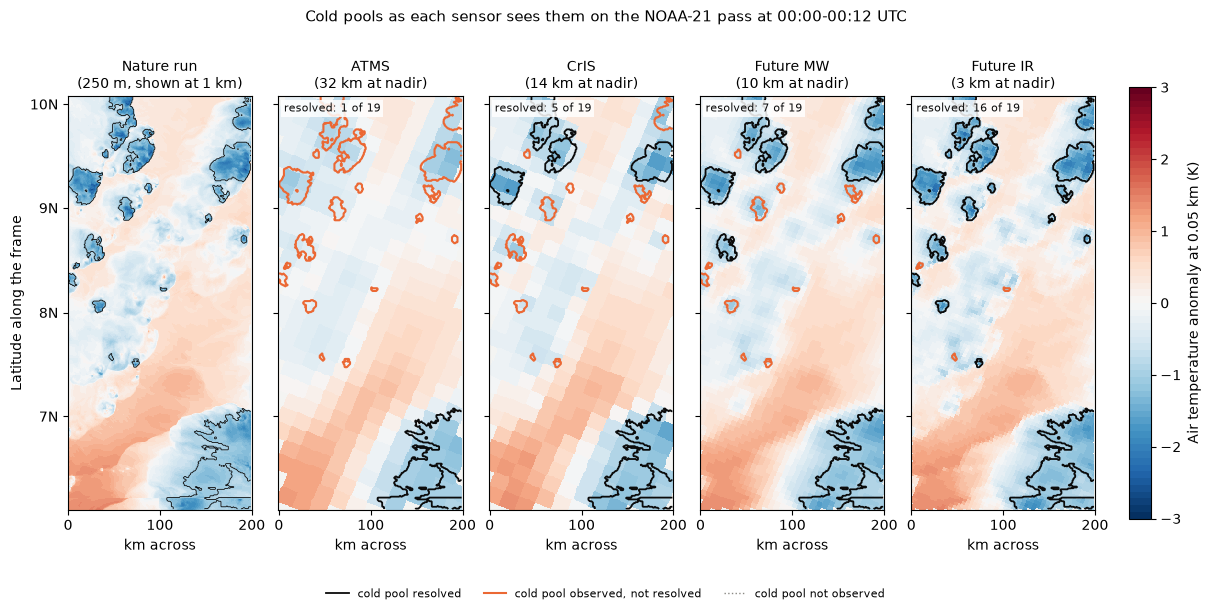

,"observed, not resolved",resolved
ATMS,18,1
CrIS,14,5
Future MW,12,7
Future IR,3,16


In [10]:
# the colormap of the anomaly, in 64 steps (of about 0.1 K), so that the animation can use a palette of its exact
# colors
CMAP, NORM = plt.get_cmap("RdBu_r", 64), plt.Normalize(-3, 3)
segment_along = np.arange(segment_rows.start, segment_rows.stop) * CELL_KM
segment_ticks = [
    k
    for k in range(-90, 91)
    if lat_center[segment_rows].min() <= k <= lat_center[segment_rows].max()
]


def rasterize(s):
    """A sensor's image of the stretch on the 1 km grid: each cell takes the value and time of the sample whose tile
    (of the sample spacing, along and across track) covers it, the nearest one where tiles overlap, and NaN where
    none does."""
    shape = (segment_rows.stop - segment_rows.start, len(across))
    value, seconds, distance = (
        np.full(shape, np.nan),
        np.full(shape, np.nan),
        np.full(shape, np.inf),
    )
    for sample in s.itertuples():
        reach = max(
            sample.spacing_along,
            sample.spacing_cross,
            sample.sample_along,
            sample.sample_cross,
        )
        rows = np.arange(
            max(segment_rows.start, int(sample.along - reach)),
            min(segment_rows.stop, int(sample.along + reach) + 2),
        )
        columns = np.arange(
            max(0, int(sample.across - reach)),
            min(len(across), int(sample.across + reach) + 2),
        )
        d_along = rows[:, None] * CELL_KM - sample.along
        d_across = columns[None, :] * CELL_KM - sample.across
        cross = d_along * sample.cross_along + d_across * sample.cross_across
        along = -d_along * sample.cross_across + d_across * sample.cross_along
        # tiles slightly larger than the spacing (TILE), so that no cell between them is missed (the nearest sample
        # takes a cell where they overlap)
        inside = (np.abs(cross) <= TILE * sample.spacing_cross / 2) & (
            np.abs(along) <= TILE * sample.spacing_along / 2
        )
        r = np.hypot(cross, along)
        nearer = inside & (
            r < distance[rows[:, None] - segment_rows.start, columns[None, :]]
        )
        i, j = np.nonzero(nearer)
        i_frame, j_frame = rows[i] - segment_rows.start, columns[j]
        value[i_frame, j_frame] = sample.value
        seconds[i_frame, j_frame] = (sample.time - start).total_seconds()
        distance[i_frame, j_frame] = r[i, j]
    return value, seconds


images = {sensor: rasterize(s) for sensor, s in samples.items()}


from matplotlib.lines import Line2D

# whether each sensor observes and resolves each cold pool on this pass alone (from the satellite's looks in the pass)
pass_looks = looks[
    (looks.satellite == pass_satellite)
    & looks.time.between(
        pass_times.min() - timedelta(seconds=TIME_STEP),
        pass_times.max() + timedelta(seconds=TIME_STEP),
    )
].reset_index(drop=True)
pass_results = assess(pass_looks, features, satellites)
# the labels of the cold pools in the stretch
segment_labels = feature_labels[segment_rows]
stretch_labels = np.unique(segment_labels[segment_labels > 0])
OUTLINES = {  # the outline of a cold pool by its status: color, width, style
    "resolved": (INK, 1.3, "solid"),
    "observed, not resolved": (ORANGE, 1.5, "solid"),
    "not observed": (GRAY, 1.0, "dotted"),
    "not yet scanned": (GRAY, 0.6, "solid"),
}


def pass_status(sensor):
    """The status of each cold pool in the stretch (by label) for a sensor on the pass."""
    r = pass_results[pass_results.sensor == sensor]
    status = np.where(
        r.resolved,
        "resolved",
        np.where(r.observed, "observed, not resolved", "not observed"),
    )
    status = pd.Series(status, index=features.label.values[r.feature.values])
    return status.loc[stretch_labels]


statuses = {sensor: pass_status(sensor) for sensor in sensors.index}


def draw_outlines(ax, groups):
    """Outlines of the cold pools of each group (a status and the labels of its cold pools); returns the contours."""
    contours = []
    for status, labels in groups.items():
        if len(labels):
            color, width, style = OUTLINES[status]
            contours.append(
                ax.contour(
                    across,
                    segment_along,
                    np.isin(segment_labels, labels),
                    levels=[0.5],
                    colors=color,
                    linewidths=width,
                    linestyles=style,
                )
            )
    return contours


def tally(sensor, labels):
    """The count of the cold pools that a sensor resolves among some (by label), of those in the stretch."""
    resolved = (statuses[sensor].loc[labels] == "resolved").sum() if len(labels) else 0
    return f"resolved: {resolved} of {len(stretch_labels)}"


def draw_views(fig, statuses_shown=OUTLINES):
    """Panels of the nature run and of each sensor's image of the stretch, with the cold pools outlined (in the
    nature run) and outlined by their status on the pass (in each sensor's image), and a legend of the statuses
    shown; returns the axes, the image of each sensor, its outlines, and its count of resolved cold pools.
    """
    axes = fig.subplots(1, 1 + len(sensors), sharey=True)
    extent = [
        -CELL_KM / 2,
        across[-1] + CELL_KM / 2,
        segment_along[0] - CELL_KM / 2,
        segment_along[-1] + CELL_KM / 2,
    ]
    shown, outlines, tallies = {}, {}, {}
    for ax, name in zip(axes, ["Nature run", *sensors.index]):
        field = anomaly[segment_rows] if name == "Nature run" else images[name][0]
        shown[name] = ax.imshow(
            field,
            cmap=CMAP,
            norm=NORM,
            origin="lower",
            extent=extent,
            interpolation="nearest",
        )
        if name == "Nature run":
            ax.set_title("Nature run\n(250 m, shown at 1 km)", fontsize=10)
            ax.contour(
                across,
                segment_along,
                in_feature[segment_rows],
                levels=[0.5],
                colors=INK,
                linewidths=0.6,
            )
        else:
            ax.set_title(
                f"{name}\n({sensors.loc[name, 'horizontal_km']} km at nadir)",
                fontsize=10,
            )
            status = statuses[name]
            outlines[name] = draw_outlines(
                ax,
                {label: status.index[status == label] for label in OUTLINES},
            )
            tallies[name] = ax.text(
                0.03,
                0.985,
                tally(name, stretch_labels),
                transform=ax.transAxes,
                va="top",
                fontsize=8,
                color=INK,
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.85,
                    "pad": 2,
                },
            )
        ax.set(aspect="equal", xticks=[0, 100, 200])
        ax.set_facecolor("#f4f4f2")
        ax.grid(False)
        ax.set_xlabel("km across")
    axes[0].set_yticks(
        [
            segment_along[np.abs(lat_center[segment_rows] - k).argmin()]
            for k in segment_ticks
        ],
        [f"{abs(k)}{'N' if k > 0 else 'S'}" for k in segment_ticks],
    )
    axes[0].set_ylabel("Latitude along the frame")
    fig.colorbar(
        shown["Nature run"],
        ax=axes,
        shrink=0.8,
        pad=0.02,
        label="Air temperature anomaly at 0.05 km (K)",
    )
    fig.legend(
        handles=[
            Line2D([], [], color=color, lw=width, ls=style, label=f"cold pool {label}")
            for label, (color, width, style) in OUTLINES.items()
            if label in statuses_shown
        ],
        loc="outside lower center",
        ncols=len(statuses_shown),
        fontsize=8,
        frameon=False,
    )
    return axes, shown, outlines, tallies


fig = plt.figure(figsize=(12, 6), layout="constrained")
draw_views(fig, statuses_shown=["resolved", "observed, not resolved", "not observed"])
fig.suptitle(
    f"Cold pools as each sensor sees them on the {pass_satellite} pass at "
    f"{pass_times.min():%H:%M}-{pass_times.max():%H:%M} UTC",
    fontsize=11,
)
plt.show()
pd.DataFrame(
    {sensor: status.value_counts() for sensor, status in statuses.items()}
).fillna(0).astype(int).T

The stretch with the most cold pools is at 6 to 10 N, where the line of thunderstorms north of the ITCZ meets the frame, and NOAA-21's pass views it near nadir, where ATMS's footprints are about 35 km across track and 33 km along it (median), and CrIS's 15 by 15 km. On this pass, ATMS resolves 1 of the 19 cold pools in the stretch (the large one at the bottom), CrIS 5, a future microwave sounder 7, and a future infrared sounder 16; the others are observed but not resolved. ATMS shows only the largest cold pools, as faint cool patches, and blurs the rest into a weak, broad cool anomaly; CrIS shows the larger cold pools as a few cool tiles; a future microwave sounder shows most cold pools larger than about 20 km, with roughly their shapes; and a future infrared sounder shows nearly all of them, with their shapes and intensity.

The animation builds each sensor's image scan by scan as the satellite passes (the black line is each sensor's latest scan), with each cold pool outlined in thin gray until the sensor has scanned all of it, then by its status, and the count of the cold pools resolved rising as the pass proceeds. The animation is saved as a GIF in the `data` directory (it is not embedded here, for its size). The scans sweep diagonally across the frame, because the satellite's ground track crosses it at an angle.

In [11]:
from matplotlib.colors import to_hex
from PIL import Image as PILImage

FRAME_SECONDS = 2  # s of the pass per frame of the animation
FPS = 10  # frames per second of the animation
HOLD_FRAMES = 20  # frames that hold the complete images at the end
DPI = 80  # pixels per inch of the animation


def save_gif(fig, update, n_frames, path, fps, colors):
    """Saves an animation as a GIF with one layout and one palette for all frames (a ramp of grays and the given
    colors), without dithering: a palette chosen for each frame (as by matplotlib's writer) shifts the colors of the
    images and the color bar from frame to frame as the colors on screen change."""
    grays = [(v, v, v) for v in np.linspace(0, 255, 96).round().astype(int)]
    rgb = grays + [
        tuple(int(color[i : i + 2], 16) for i in (1, 3, 5)) for color in colors
    ]
    palette = PILImage.new("P", (1, 1))
    palette.putpalette(
        [v for color in rgb for v in color] + [255] * 3 * (256 - len(rgb))
    )
    fig.set_dpi(DPI)
    # lay the figure out once and keep it: a layout recomputed for each frame (as its titles change) moves the
    # panels and color bar by a pixel or so from frame to frame
    update(0)
    fig.canvas.draw()
    fig.set_layout_engine("none")
    frames = []
    for k in range(n_frames):
        update(k)
        fig.canvas.draw()
        image = PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3])
        frames.append(image.quantize(palette=palette, dither=PILImage.Dither.NONE))
    frames[0].save(
        path,
        save_all=True,
        append_images=frames[1:],
        duration=round(1000 / fps),
        loop=0,
        optimize=True,
    )


ANIMATION_FILE = DATA_DIR / "cold_pools_sensor_views.gif"

first = min(s.time.min() for s in samples.values())
last = max(s.time.max() for s in samples.values())
frame_times = pd.date_range(
    first, last + pd.Timedelta(seconds=FRAME_SECONDS), freq=f"{FRAME_SECONDS}s"
)
# the time (s from the start of the window) at which each sensor has scanned all of each cold pool in the stretch
# that it scans (its last cell), or infinity if it scans none of it
scanned_at = {}
for sensor in sensors.index:
    seconds = images[sensor][1]
    latest = ndi.maximum(
        np.where(np.isnan(seconds), -np.inf, seconds), segment_labels, stretch_labels
    )
    scanned_at[sensor] = pd.Series(
        np.where(np.isfinite(latest), latest, np.inf), index=stretch_labels
    )

fig = plt.figure(figsize=(12, 6), layout="constrained")
axes, shown, outlines, tallies = draw_views(fig)
title = fig.suptitle("", fontsize=11)
scan_lines = {
    sensor: ax.plot([], [], color=INK, lw=1.5, solid_capstyle="round")[0]
    for ax, sensor in zip(axes[1:], sensors.index)
}


def update(k):
    """Shows the samples up to the time of animation frame k (the complete images after the last time), with the
    cold pools outlined by their status once they are scanned."""
    t = frame_times[min(k, len(frame_times) - 1)]
    elapsed = (t - start).total_seconds()
    for ax, (sensor, s) in zip(axes[1:], samples.items()):
        value, seconds = images[sensor]
        shown[sensor].set_data(np.where(seconds <= elapsed, value, np.nan))
        observed = (s.time <= t).values
        if observed.any() and k < len(frame_times):
            scan = s[s.time == s.time[observed].max()].sort_values("across")
            scan_lines[sensor].set_data(scan.across, scan.along)
        else:
            scan_lines[sensor].set_data([], [])
        # outlines by status of the cold pools scanned so far, and the others as not yet scanned
        while outlines[sensor]:
            outlines[sensor].pop().remove()
        status = statuses[sensor]
        done = scanned_at[sensor] <= elapsed
        if k >= len(frame_times):
            done = scanned_at[sensor] < np.inf
        groups = {label: status.index[(status == label) & done] for label in OUTLINES}
        groups["not yet scanned"] = status.index[~done & (status != "not observed")]
        groups["not observed"] = status.index[status == "not observed"]
        outlines[sensor] = draw_outlines(ax, groups)
        tallies[sensor].set_text(tally(sensor, status.index[done]))
    title.set_text(
        f"Cold pools as each sensor sees them: {pass_satellite}, {t:%H:%M:%S} UTC "
        f"(nature run of {NATURE_TIME:%d %B %Y}, {NATURE_TIME:%H:%M} UTC)"
    )


# the palette: the colormap's colors, and those of the outlines (with the grays of the background and text)
save_gif(
    fig,
    update,
    len(frame_times) + HOLD_FRAMES,
    ANIMATION_FILE,
    FPS,
    colors=[to_hex(CMAP(i)) for i in range(CMAP.N)] + [INK, ORANGE, GRAY],
)
plt.close(fig)
print(
    f"{ANIMATION_FILE}: {len(frame_times) + HOLD_FRAMES} frames, {(last - first).total_seconds():.0f} s of the pass, "
    f"{ANIMATION_FILE.stat().st_size / 1e6:.1f} MB"
)

data\cold_pools_sensor_views.gif: 58 frames, 74 s of the pass, 0.3 MB


## Generate Statistics

The table gives, for each sensor, the share of the cold pools that it observes and resolves, the share of their total area that lies in resolved cold pools, and the median resolution element and zenith angle of its best looks at the observed cold pools.

In [12]:
def summarize(r):
    """Shares (%) of the features observed and resolved and of their area in resolved features, and the median
    resolution element and zenith angle of the best looks."""
    return pd.Series(
        {
            "features": len(r),
            "observed (%)": 100 * r.observed.mean(),
            "resolved (%)": 100 * r.resolved.mean(),
            "resolved, in quadrature (%)": 100
            * (r["elements (quadrature)"] >= RESOLUTION_FACTOR).mean(),
            "resolved (% of area)": 100
            * r.area_km2[r.resolved].sum()
            / r.area_km2.sum(),
            "median element of observed (km)": r.element_km[r.observed].median(),
            "median zenith of observed (deg)": r.zenith[r.observed].median(),
        }
    )


summary = (
    results.groupby("sensor").apply(summarize, include_groups=False).loc[sensors.index]
)
summary.round(1)

,features,observed (%),resolved (%),"resolved, in quadrature (%)",resolved (% of area),median element of observed (km),median zenith of observed (deg)
sensor,,,,,,,
ATMS,149.0,100.0,0.7,0.0,12.6,36.5,24.7
CrIS,149.0,100.0,6.7,2.7,50.6,18.0,24.7
Future MW,149.0,100.0,15.4,12.1,71.9,11.4,24.7
Future IR,149.0,100.0,65.8,43.6,96.1,3.7,24.7


Resolution, not coverage, separates the sensors. ATMS resolves 1 of the 149 cold pools, the largest (79 km), which holds 13% of their area. CrIS resolves 10 (7%), which hold 51% of the area, a future microwave sounder 23 (15%, with 72% of the area), and a future infrared sounder 98 (66%, with 96% of the area). The median resolution elements of the best looks (37, 18, 11, and 3.7 km) are larger than the nominal ones, because the best looks are about 25 degrees from nadir.

Many cold pools are near the smallest feature that a future infrared sounder resolves, so its share depends on how the resolution element is defined. With the footprint and the spacing added in quadrature (a bound on the element where the two are similar, as for the infrared sounders, whose views are spaced by little more than their size), a future infrared sounder resolves 44% of the cold pools instead of 66%, CrIS 3% instead of 7%, a future microwave sounder 12% instead of 15%, and ATMS none. A future infrared sounder still resolves several times as many as any other sensor.

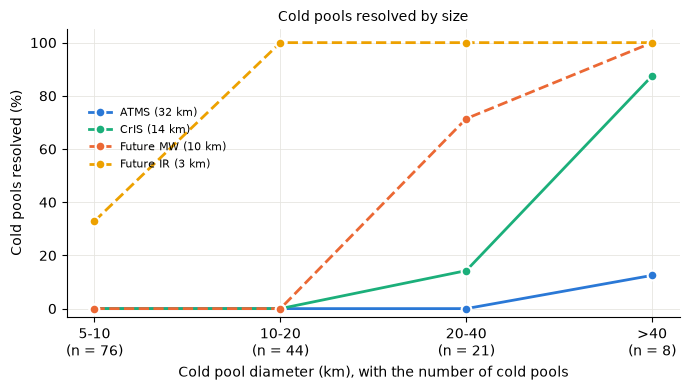

In [13]:
SENSOR_COLORS = {"ATMS": BLUE, "Future MW": ORANGE, "CrIS": AQUA, "Future IR": YELLOW}
SENSOR_STYLES = {"ATMS": "-", "Future MW": "--", "CrIS": "-", "Future IR": "--"}
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
    }
)

edges = np.array([MIN_DIAMETER_KM, 10, 20, 40, np.inf])
labels = [f"{MIN_DIAMETER_KM}-10", "10-20", "20-40", ">40"]
results["size_class"] = pd.cut(results.diameter_km, edges, labels=labels, right=False)
by_size = (
    results.groupby(["sensor", "size_class"], observed=False)
    .resolved.mean()
    .unstack()
    .loc[sensors.index]
    * 100
)
counts = results[results.sensor == "ATMS"].groupby("size_class", observed=False).size()

fig, ax = plt.subplots(figsize=(7, 4))
for sensor in sensors.index:
    ax.plot(
        labels,
        by_size.loc[sensor],
        marker="o",
        ms=7,
        lw=2,
        mec="white",
        mew=1.5,
        color=SENSOR_COLORS[sensor],
        ls=SENSOR_STYLES[sensor],
        label=f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)",
    )
ax.set_xticks(
    range(len(labels)), [f"{label}\n(n = {n})" for label, n in zip(labels, counts)]
)
ax.set(
    xlabel="Cold pool diameter (km), with the number of cold pools",
    ylabel="Cold pools resolved (%)",
    ylim=(-3, 105),
    title="Cold pools resolved by size",
)
ax.title.set_fontsize(10)
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(0.02, 0.62))
fig.tight_layout()
plt.show()

By size, half of the cold pools (76 of 149) are smaller than 10 km, which only a future infrared sounder resolves (33% of them); it resolves every larger one. A future microwave sounder resolves most of those of 20 km or more, CrIS only some of those of 20 to 40 km and most of those of 40 km or more (7 of 8), and ATMS only the largest. This follows from requiring two resolution elements across a feature: a 10 km sounder resolves features of about 20 km, and a 3 km sounder of about 7 km. The counts of the larger classes are small (8 to 44 cold pools), so their shares are uncertain by tens of percentage points.

## Trade the Constellation Design

The constellation trade of the [monsoon OSSE](RunOSSEMonsoon.ipynb) compares numbers of satellites and orbit planes over two weeks of convection. Here, with a single snapshot, the same designs are compared on how many of the cold pools they observe and resolve within the window around the snapshot. The answer depends on the snapshot's local time (about 13:00) and on the window, so it applies to this scene: cold pools at another time of day, or that last longer, would favor different designs.

Each design places satellites in sun-synchronous orbits at 830 km, in planes whose ascending equator crossing times are spread evenly over 12 hours from 13:30, with the satellites of each plane evenly spaced at a random phase; each carries both swaths. The designs are all satellites in one plane and one satellite per plane, for 1 to 6 satellites, and 6 satellites in 2 planes. Which passes cross the frame in the window depends strongly on the phase, so each design is evaluated for `N_DRAWS` random phases, and the results averaged.

In [14]:
from datetime import time as time_of_day

from tatc.schemas import SunSynchronousOrbit

N_DRAWS = 20  # random phases of the satellites in their planes, per design
# designs (planes, satellites per plane): all in one plane, one per plane, and 6 satellites in 2 planes
DESIGNS = [(1, n) for n in range(1, 7)] + [(n, 1) for n in range(2, 7)] + [(2, 3)]


def constellation(n_planes, per_plane, rng):
    """Satellites in n_planes sun-synchronous planes at 830 km, whose ascending equator crossing times are spread evenly
    over 12 hours from 13:30, with per_plane satellites evenly spaced in each plane at a random phase.
    """
    members = []
    for p in range(n_planes):
        hours = (13.5 + 12 * p / n_planes) % 24
        crossing = time_of_day(int(hours), round(60 * (hours % 1)) % 60)
        phase = rng.uniform(0, 360)
        for s in range(per_plane):
            orbit = SunSynchronousOrbit(
                altitude=830e3,
                equator_crossing_time=crossing,
                epoch=snapshot,
                true_anomaly=(phase + 360 * s / per_plane) % 360,
            )
            members.append(sounder_satellite(f"plane {p + 1} satellite {s + 1}", orbit))
    return members


def evaluate(members):
    """The share (%) of the features that each sensor observes and resolves, flown on the members."""
    looks = collect_looks(members, features)
    return (
        assess(looks, features, members)
        .groupby("sensor")[["observed", "resolved"]]
        .mean()
        .mul(100)
    )


rng = np.random.default_rng(0)
trade = pd.concat(
    [
        evaluate(constellation(n_planes, per_plane, rng)).assign(
            planes=n_planes, per_plane=per_plane, draw=draw
        )
        for n_planes, per_plane in DESIGNS
        for draw in range(N_DRAWS)
    ]
).reset_index()
trade["satellites"] = trade.planes * trade.per_plane
trade["design"] = (
    trade.planes.astype(str) + " plane(s) x " + trade.per_plane.astype(str)
)
current = evaluate(satellites).assign(
    satellites=len(satellites), design=f"current ({len(satellites)} in the 13:30 plane)"
)

# features observed (by each swath) and resolved (by each sensor), % of all features, averaged over the draws
trade_summary = pd.concat([trade, current.reset_index()]).pivot_table(
    index=["satellites", "design"], columns="sensor", values=["observed", "resolved"]
)
trade_summary = pd.concat(
    [
        trade_summary["observed"][["ATMS", "CrIS"]]
        .add_prefix("observed, ")
        .add_suffix(" swath"),
        trade_summary["resolved"][sensors.index].add_prefix("resolved, "),
    ],
    axis=1,
)
trade_summary.round(1)

sensor                                     observed, ATMS swath  \
satellites design                                                 
1          1 plane(s) x 1                                  85.8   
2          1 plane(s) x 2                                 100.0   
           2 plane(s) x 1                                  78.1   
           current (2 in the 13:30 plane)                 100.0   
3          1 plane(s) x 3                                 100.0   
           3 plane(s) x 1                                  79.0   
4          1 plane(s) x 4                                 100.0   
           4 plane(s) x 1                                  84.0   
5          1 plane(s) x 5                                 100.0   
           5 plane(s) x 1                                  82.0   
6          1 plane(s) x 6                                 100.0   
           2 plane(s) x 3                                 100.0   
           6 plane(s) x 1                                  82.7   

sensor                                     observed, CrIS swath  \
satellites design                                                 
1          1 plane(s) x 1                                  74.2   
2          1 plane(s) x 2                                  99.6   
           2 plane(s) x 1                                  67.3   
           current (2 in the 13:30 plane)                 100.0   
3          1 plane(s) x 3                                 100.0   
           3 plane(s) x 1                                  66.2   
4          1 plane(s) x 4                                 100.0   
           4 plane(s) x 1                                  72.5   
5          1 plane(s) x 5                                 100.0   
           5 plane(s) x 1                                  70.5   
6          1 plane(s) x 6                                 100.0   
           2 plane(s) x 3                                 100.0   
           6 plane(s) x 1                                  65.1   

sensor                                     resolved, ATMS  resolved, CrIS  \
satellites design                                                           
1          1 plane(s) x 1                             0.3             3.8   
2          1 plane(s) x 2                             0.5             5.8   
           2 plane(s) x 1                             0.2             3.5   
           current (2 in the 13:30 plane)             0.7             6.7   
3          1 plane(s) x 3                             0.7             6.7   
           3 plane(s) x 1                             0.2             3.0   
4          1 plane(s) x 4                             0.7             6.9   
           4 plane(s) x 1                             0.3             3.7   
5          1 plane(s) x 5                             0.7             6.9   
           5 plane(s) x 1                             0.3             3.9   
6          1 plane(s) x 6                             0.7             7.2   
           2 plane(s) x 3                             0.6             6.6   
           6 plane(s) x 1                             0.1             2.8   

sensor                                     resolved, Future MW  \
satellites design                                                
1          1 plane(s) x 1                                  9.8   
2          1 plane(s) x 2                                 14.7   
           2 plane(s) x 1                                  8.6   
           current (2 in the 13:30 plane)                 15.4   
3          1 plane(s) x 3                                 16.9   
           3 plane(s) x 1                                  8.5   
4          1 plane(s) x 4                                 17.4   
           4 plane(s) x 1                                  9.4   
5          1 plane(s) x 5                                 17.9   
           5 plane(s) x 1                                  9.2   
6          1 plane(s) x 6               

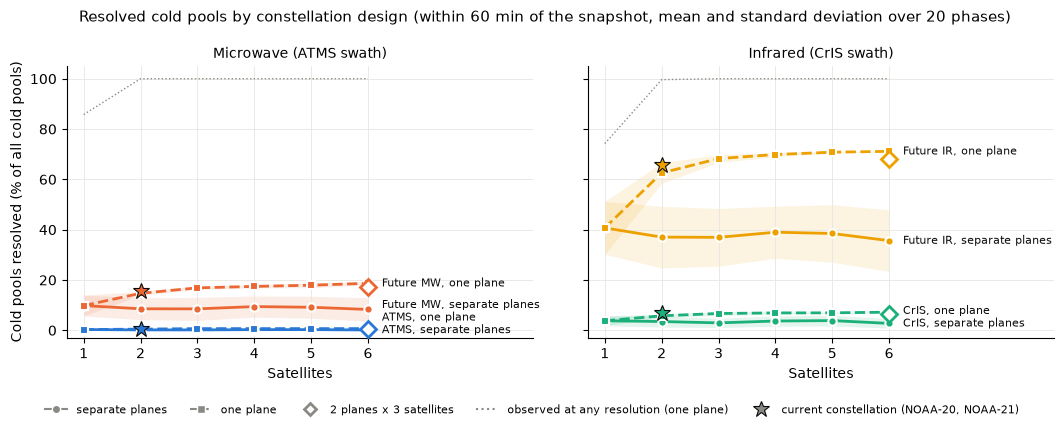

In [15]:
STRATEGIES = {"separate planes": ("-", "o"), "one plane": ("--", "s")}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (title, pair) in zip(
    axes,
    {
        "Microwave (ATMS swath)": ("ATMS", "Future MW"),
        "Infrared (CrIS swath)": ("CrIS", "Future IR"),
    }.items(),
):
    ends = []
    for sensor in pair:
        color = SENSOR_COLORS[sensor]
        for strategy, (ls, marker) in STRATEGIES.items():
            selected = trade[
                (trade.sensor == sensor)
                & (
                    (trade.planes == 1)
                    if strategy == "one plane"
                    else (trade.per_plane == 1)
                )
            ]
            stats = selected.groupby("satellites")["resolved"].agg(["mean", "std"])
            ax.fill_between(
                stats.index,
                stats["mean"] - stats["std"],
                stats["mean"] + stats["std"],
                color=color,
                alpha=0.12,
                lw=0,
            )
            ax.plot(
                stats.index,
                stats["mean"],
                ls=ls,
                marker=marker,
                ms=6,
                lw=2,
                color=color,
                mec="white",
                mew=1.5,
            )
            ends.append([stats["mean"].iloc[-1], f"{sensor}, {strategy}"])
        two_planes = trade[
            (trade.sensor == sensor) & (trade.planes == 2) & (trade.per_plane == 3)
        ]["resolved"].mean()
        ax.plot(
            6, two_planes, marker="D", ms=8, color="white", mec=color, mew=2, zorder=3
        )
        ax.plot(
            len(satellites),
            current.loc[sensor, "resolved"],
            marker="*",
            ms=12,
            color=color,
            mec=INK,
            mew=0.8,
            zorder=4,
        )
    # direct labels at the line ends, nudged apart so that they do not overlap
    ends.sort()
    for i in range(1, len(ends)):
        ends[i][0] = max(ends[i][0], ends[i - 1][0] + 5)
    for y, label in ends:
        ax.annotate(
            label,
            (6, y),
            xytext=(10, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
            color=INK,
        )
    # the features observed at any resolution, with all satellites in one plane: the most that any sensor can resolve
    observed = (
        trade[(trade.sensor == pair[0]) & (trade.planes == 1)]
        .groupby("satellites")["observed"]
        .mean()
    )
    ax.plot(observed.index, observed, color=GRAY, lw=1, ls=":")
    ax.set(
        title=title,
        xlabel="Satellites",
        xticks=range(1, 7),
        xlim=(0.7, 8.9),
        ylim=(-3, 105),
    )
    ax.title.set_fontsize(10)
axes[0].set_ylabel("Cold pools resolved (% of all cold pools)")
legend = [
    plt.Line2D(
        [], [], color=GRAY, ls="-", marker="o", mec="white", label="separate planes"
    ),
    plt.Line2D([], [], color=GRAY, ls="--", marker="s", mec="white", label="one plane"),
    plt.Line2D(
        [],
        [],
        color=GRAY,
        ls="none",
        marker="D",
        mfc="white",
        mew=2,
        label="2 planes x 3 satellites",
    ),
    plt.Line2D(
        [], [], color=GRAY, ls=":", label="observed at any resolution (one plane)"
    ),
    plt.Line2D(
        [],
        [],
        color=GRAY,
        ls="none",
        marker="*",
        ms=12,
        mec=INK,
        mew=0.8,
        label=f"current constellation ({', '.join(tles)})",
    ),
]
fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.suptitle(
    f"Resolved cold pools by constellation design (within {HALF_WINDOW.seconds // 60} min of the snapshot, mean and standard deviation over {N_DRAWS} phases)",
    fontsize=11,
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In this scene, the number of satellites in the afternoon plane matters, the number of planes hardly does, and the sensors matter most. The current constellation of two satellites (stars) resolves about as many cold pools as two satellites evenly spaced in its plane.

* **One plane saturates observation.** Two satellites in the 13:30 plane observe nearly every cold pool within an hour of the snapshot, against 74 to 86% for one. More satellites add views closer to nadir, which raise the share that a future infrared sounder resolves from 41% with one satellite to 71% with six.
* **Separate planes do not help a snapshot.** Satellites in planes at other local times pass over the frame hours from its time, so a design of one satellite per plane resolves about as many cold pools as a single satellite (36 to 39% for a future infrared sounder), however many planes it has. (In the designs of two planes, the second plane descends in the early afternoon, but its ground track runs parallel to the frame, which it covers only on the days it passes close to it.) This is the reverse of the monsoon trade, in which convection through the day over two weeks rewards a spread of local times. A feature that lasts an hour rewards satellites that pass within that hour.
* **Resolution dominates.** A single satellite with a future infrared sounder resolves 41% of the cold pools, more than five times as many as six satellites with CrIS (7%). ATMS resolves less than 1% in every design, and a future microwave sounder at most 19%.

The shaded bands (one standard deviation over the random phases) are wide for designs with few satellites in the afternoon plane, whose passes miss the frame on some draws.

## Limitations

The limitations of the monsoon OSSE apply, notably that resolution is geometric (the larger of the nominal footprint and the sample spacing, without the response of each footprint, which is optimistic for the infrared sounders; see the statistics for the quadrature bound) and that the future sensors are assumed to share the swaths and platforms of ATMS and CrIS. In addition:

* **One snapshot of one scene.** The results describe one simulated scene at one time of day, observed by one realization of the satellites' passes (the constellation trade averages over the phases of the satellites, not over scenes). Other scenes, seasons, and times of day would be needed for statistics, and nature runs with output every few minutes would allow the cold pools to evolve during the window instead of being frozen in it.
* **The window is a choice.** The snapshot is assumed to represent the scene for an hour on either side of its time (`HALF_WINDOW`), roughly the lifetime of a cold pool. A shorter window would observe fewer cold pools with the current constellation, and favor more satellites in the afternoon plane still more.
* **The frame is narrow.** At 200 km across, the frame is narrower than the sounders' swaths, so 21 of the 149 cold pools touch its long edges and may extend beyond them, and the footprints near its edges are averaged over the part inside it.
* **The cold pools are defined from temperature alone.** A threshold of -1 K at 0.05 km below a smoothed background, with a minimum size of 5 km, is one of several common definitions; others use the density or buoyancy of the air, which includes its moisture, or the drop in temperature at a point over time. The front at the southern end of the frame is excluded, and the seams between the frame's 13 domains, every 500 km, cut a few cold pools.
* **Sounders do not measure the air temperature at 0.05 km.** The images show how each sensor's sampling blurs the anomaly near the surface, not what it would retrieve. Microwave sounders are weakly sensitive to the lowest few hundred meters, and infrared sounders see the surface only through clear sky, whereas cold pools lie under showers and thunderstorms and the clouds that spread from them.
* **The nature run is not reality.** GEM simulates the cold pools at 250 m, which resolves their larger structure but not the turbulence at their edges, and its cold pools, like its convection, differ in number and size from those observed.

## References

* Qu, Z., Donovan, D. P., Barker, H. W., Cole, J. N. S., Shephard, M. W., and Huijnen, V. (2023). Numerical model generation of test frames for pre-launch studies of EarthCARE's retrieval algorithms and data management system. *Atmospheric Measurement Techniques*, 16, 4927-4946. https://doi.org/10.5194/amt-16-4927-2023
* Qu, Z., Donovan, D. P., Barker, H. W., Cole, J. N. S., Shephard, M. W., and Huijnen, V. (2022). Numerical Model Generated Hawaii Test Scenes for EarthCARE Pre-launch Studies - Part 1: Atmospheric and Surface Properties (Version 1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.7196690 (CC BY 4.0)